In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np

In [2]:
train_dir = "data/train"
test_dir = "data/test"

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    
    # Data augmentation
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    
    transforms.ToTensor(),
    
    # Normalize RGB channels
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [4]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

In [5]:
print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Classes: ['cats', 'dogs']
Class mapping: {'cats': 0, 'dogs': 1}
Training images: 19989
Testing images: 5000


In [6]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [30]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])


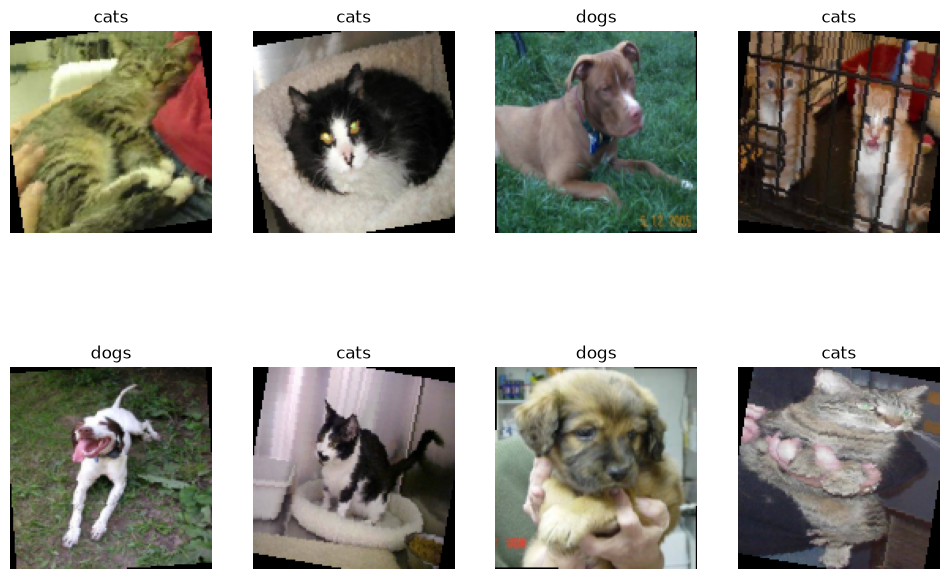

In [33]:
def show_images(images, labels, classes):
    images = images * 0.5 + 0.5

    plt.figure(figsize=(12, 8))

    for i in range(8):
        plt.subplot(2, 4, i + 1)

        img = images[i].permute(1, 2, 0)
        plt.imshow(img)

        plt.title(classes[labels[i]])
        plt.axis("off")

    plt.show()


show_images(images, labels, train_dataset.classes)

In [11]:
class CatDogCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # 128x128 → 64x64
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 64x64 → 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 32x32 → 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 16x16 → 8x8
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 8 * 8, 512),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(512, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)

        return x

In [12]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [13]:
model = CatDogCNN()

model = model.to(device)

print(model)

CatDogCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=2, bias=True)
  )
)


In [14]:
criterion = nn.CrossEntropyLoss()

In [15]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [17]:
num_epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/10] Loss: 0.6408 Accuracy: 61.74%
Epoch [2/10] Loss: 0.5231 Accuracy: 74.24%
Epoch [3/10] Loss: 0.4424 Accuracy: 79.79%
Epoch [4/10] Loss: 0.3978 Accuracy: 82.35%
Epoch [5/10] Loss: 0.3655 Accuracy: 83.90%
Epoch [6/10] Loss: 0.3316 Accuracy: 85.58%
Epoch [7/10] Loss: 0.3074 Accuracy: 86.89%
Epoch [8/10] Loss: 0.2797 Accuracy: 88.13%
Epoch [9/10] Loss: 0.2644 Accuracy: 88.93%
Epoch [10/10] Loss: 0.2511 Accuracy: 89.45%


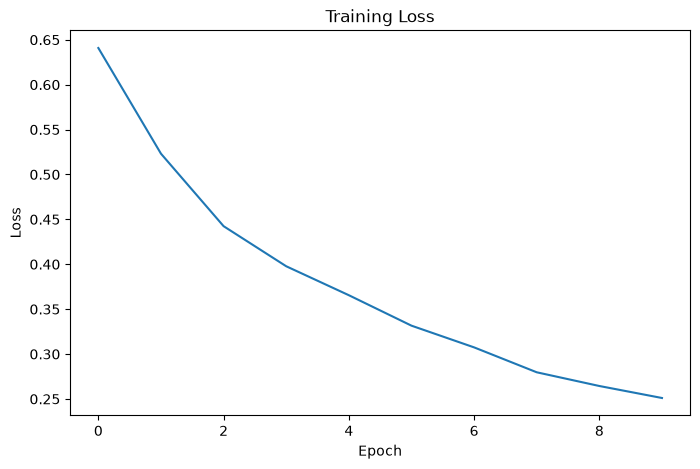

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

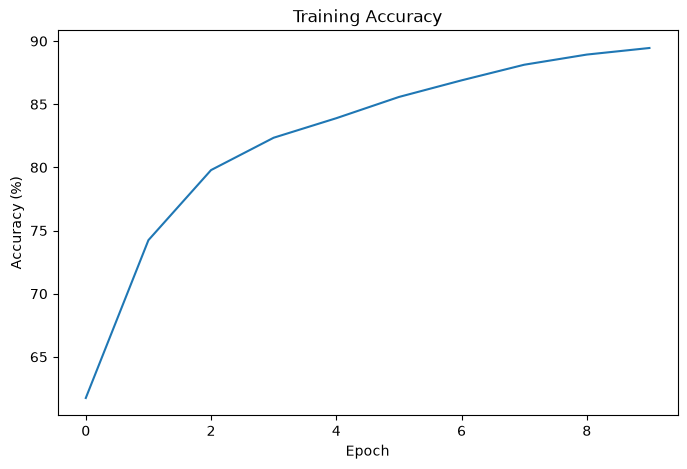

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy")

plt.show()

In [20]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 89.00%


In [21]:
from PIL import Image

def predict_image(image_path):

    image = Image.open(image_path).convert("RGB")

    image_tensor = test_transform(image)

    image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    model.eval()

    with torch.no_grad():

        output = model(image_tensor)

        probabilities = torch.softmax(output, dim=1)

        predicted_class = torch.argmax(probabilities, dim=1).item()

    class_name = train_dataset.classes[predicted_class]

    confidence = probabilities[0][predicted_class].item() * 100

    return class_name, confidence

In [24]:
image_path = "data/test/cats/cat.0.jpg"

prediction, confidence = predict_image(image_path)

print("Prediction:", prediction)
print(f"Confidence: {confidence:.2f}%")

Prediction: cats
Confidence: 97.87%


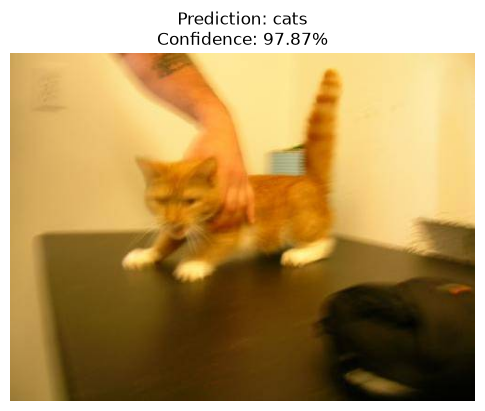

In [25]:
image = Image.open(image_path).convert("RGB")

prediction, confidence = predict_image(image_path)

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.title(
    f"Prediction: {prediction}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

In [26]:
torch.save(model.state_dict(), "cat_dog_model.pth")

print("Model saved!")

Model saved!


In [27]:
model = CatDogCNN()

model.load_state_dict(
    torch.load(
        "cat_dog_model.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Model loaded!")

Model loaded!
